# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [10]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [12]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [13]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [14]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


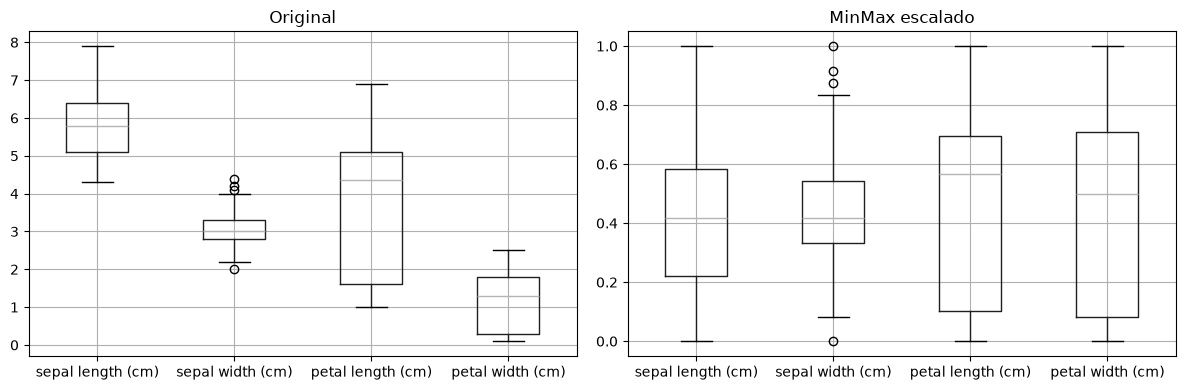

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data.boxplot(ax=axes[0])
axes[0].set_title('Original')

data_minmax.boxplot(ax=axes[1])
axes[1].set_title('MinMax escalado')

plt.tight_layout()
plt.show()

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

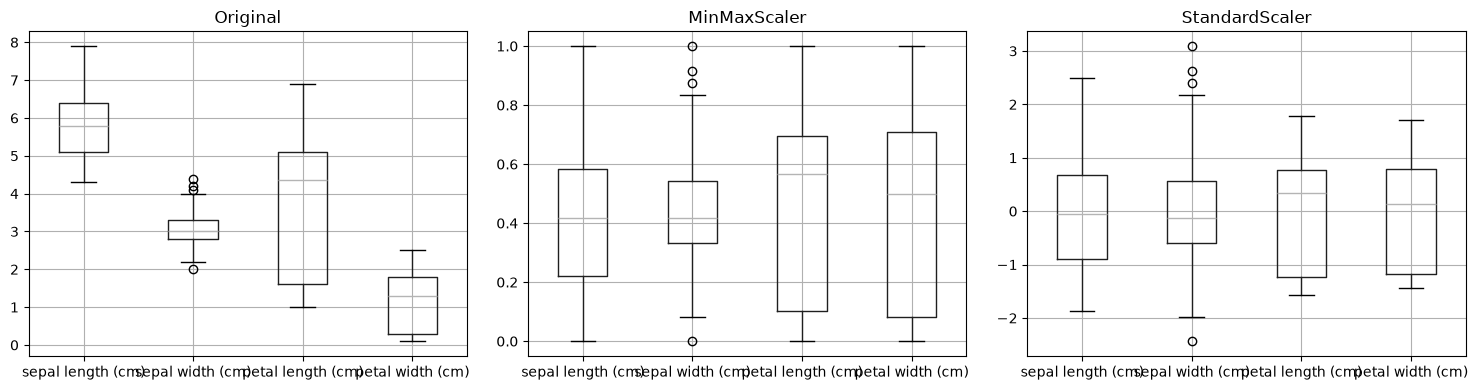

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

data.boxplot(ax=axes[0])
axes[0].set_title('Original')

data_minmax.boxplot(ax=axes[1])
axes[1].set_title('MinMaxScaler')

data_standard.boxplot(ax=axes[2])
axes[2].set_title('StandardScaler')

plt.tight_layout()
plt.show()

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

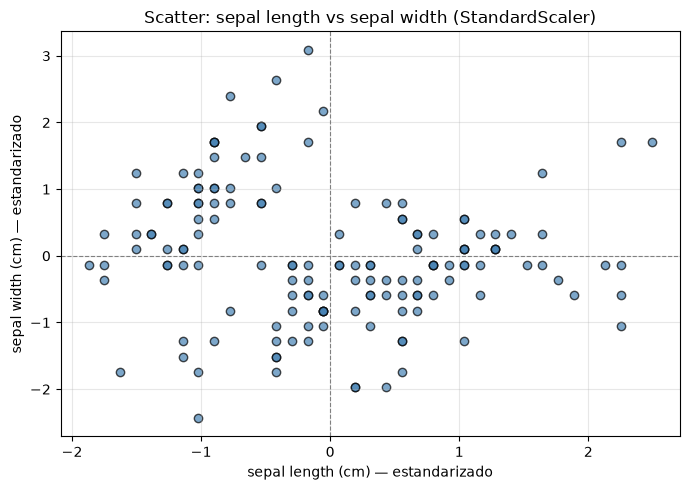

In [16]:
plt.figure(figsize=(7, 5))
plt.scatter(data_standard['sepal length (cm)'],
            data_standard['sepal width (cm)'],
            alpha=0.7, color='steelblue', edgecolor='k')

plt.title('Scatter: sepal length vs sepal width (StandardScaler)')
plt.xlabel('sepal length (cm) — estandarizado')
plt.ylabel('sepal width (cm) — estandarizado')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

In [22]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Datos
iris = load_iris(as_frame=True)
data = iris.frame.copy()
data.columns = ['sepal length (cm)', 'sepal width (cm)',
                'petal length (cm)', 'petal width (cm)', 'target']

cols = data.columns[:-1].tolist()

X = data[cols]
y = data['target']

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

pipe.fit(X_train, y_train)
acc = accuracy_score(y_test, pipe.predict(X_test))
print(f"Accuracy: {acc:.3f}")

Accuracy: 0.933
